# Сырые оси магнитометров в зависимости от силы сжатия протеза

Данные: `tools/ramp_*.csv` из `force_ramp.py` — несколько циклов, сила 10 → 100 % с шагом 1 %.
Колонки: `t_s, force_pct, THUMB_MLX0_X … MIDDLE_MLX3_Z` (сырые int16, LSB).

**Метод.** Каждый цикл делится на ступени — подряд идущие кадры с одной и той же силой (~0,5 с, ~30 кадров).
Для каждой ступени и каждой оси берётся **медиана** — она отбрасывает выбросы на переходе между ступенями.
Получается одна точка на (цикл, сила) → дискретные графики.
Ступень контакта (минимальная сила, ~2 с, в начале пальцы ещё едут к предмету) — медиана только последних `CONTACT_TAIL_S` секунд.

               t_s    force_pct       weight
count  1251.000000  1251.000000  1251.000000
mean     27.295214    23.389289  1469.279495
std      15.835014    29.882830  1356.481993
min       0.000300     0.000000    24.338000
25%      13.568700     0.000000    26.856000
50%      27.234100    10.000000  1837.713000
75%      41.030650    40.000000  1941.912500
max      54.727800   100.000000  4364.677000
 step  force_pct  t_start   t_end  n  weight_med  weight_std
    1         10   0.0003  1.9639 46   1909.8920    2.101139
    2         20   2.0141  2.1653  5   1909.2620    0.887426
    3         30   2.2105  2.3952  5   1906.6970    1.216158
    4         40   2.4456  2.5964  5   1903.1790    1.620832
    5         50   2.6426  2.7799  4   1903.2255    3.912027
    6         60   2.8267  2.9779  5   1930.0920  126.502494
    7         70   3.0281  3.1675  4   2318.9590  258.809516
    8         80   3.2137  3.3579  5   3096.5180  469.812918
    9         90   3.4087  3.5993  5   4332.61

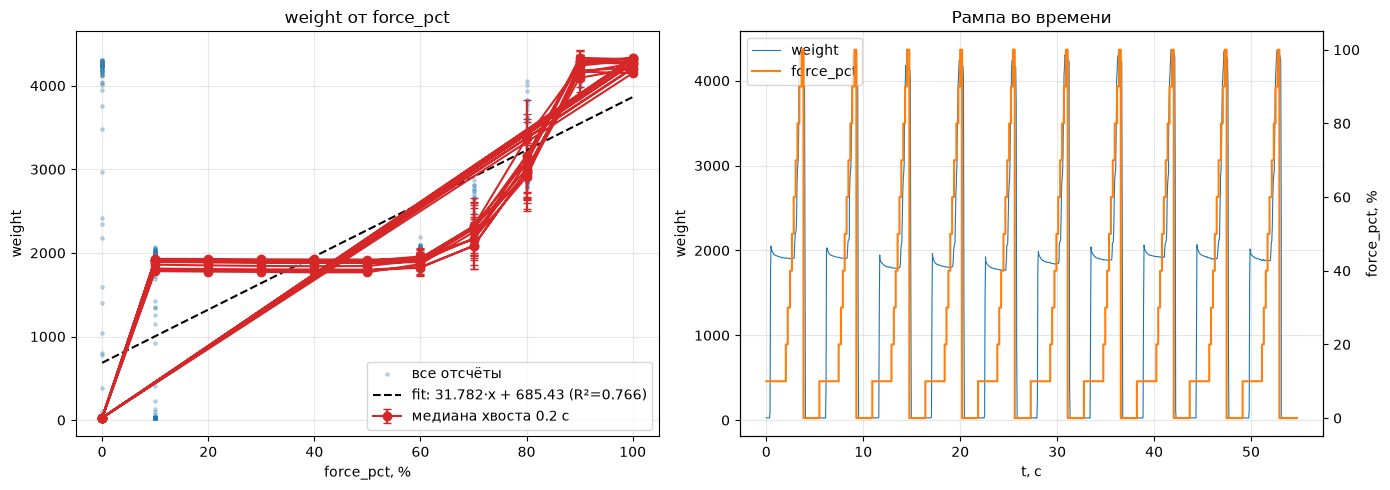

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# --- параметры (ваши)
FILE = Path('/home/max/python_projects/vtos_vtochku/tools/ramp_20261027_133828.csv')
CONTACT_TAIL_S = 0.2
SAVE_PNG = True
OUT_DIR = Path('analysis')

df = pd.read_csv(FILE)
print(df[['t_s', 'force_pct', 'weight']].describe())

# --- разбивка на ступени: новая ступень при каждой смене force_pct
df['step'] = (df['force_pct'] != df['force_pct'].shift()).cumsum()

rows = []
for step_id, g in df.groupby('step'):
    t_end = g['t_s'].max()
    tail = g[g['t_s'] >= t_end - CONTACT_TAIL_S]
    if len(tail) == 0:
        tail = g
    rows.append({
        'step': step_id,
        'force_pct': g['force_pct'].iloc[0],
        't_start': g['t_s'].min(),
        't_end': t_end,
        'n': len(g),
        'weight_med': tail['weight'].median(),
        'weight_std': tail['weight'].std(),
    })
steps = pd.DataFrame(rows)
print(steps.to_string(index=False))

# --- линейная аппроксимация weight = k * force_pct + b по медианам ступеней
x = steps['force_pct'].to_numpy(float)
y = steps['weight_med'].to_numpy(float)
k, b = np.polyfit(x, y, 1)
r2 = 1 - np.sum((y - (k * x + b))**2) / np.sum((y - y.mean())**2)
print(f'weight = {k:.4f} * force_pct + {b:.4f},  R^2 = {r2:.4f}')

# --- графики
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# 1) weight от force_pct
ax = axs[0]
ax.scatter(df['force_pct'], df['weight'], s=6, alpha=0.25, label='все отсчёты')
ax.errorbar(steps['force_pct'], steps['weight_med'], yerr=steps['weight_std'],
            fmt='o-', color='C3', capsize=3, label=f'медиана хвоста {CONTACT_TAIL_S} с')
xx = np.linspace(x.min(), x.max(), 100)
ax.plot(xx, k * xx + b, '--', color='k', label=f'fit: {k:.3f}·x + {b:.2f} (R²={r2:.3f})')
ax.set_xlabel('force_pct, %')
ax.set_ylabel('weight')
ax.set_title('weight от force_pct')
ax.grid(alpha=0.3)
ax.legend()

# 2) по времени
ax = axs[1]
ax.plot(df['t_s'], df['weight'], lw=0.8, label='weight')
ax.set_xlabel('t, с')
ax.set_ylabel('weight')
ax2 = ax.twinx()
ax2.step(df['t_s'], df['force_pct'], where='post', color='C1', label='force_pct')
ax2.set_ylabel('force_pct, %')
ax.set_title('Рампа во времени')
ax.grid(alpha=0.3)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left')

plt.tight_layout()
if SAVE_PNG:
    OUT_DIR.mkdir(exist_ok=True)
    plt.savefig(OUT_DIR / f'{FILE.stem}_weight_vs_force.png', dpi=150)
plt.show()

In [4]:
import csv
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# --- параметры
FILE = Path('/home/max/python_projects/vtos_vtochku/tools/ramp_20261027_133256.csv')   # путь относительно папки ноутбука
CONTACT_TAIL_S = 0.2     # для ступени контакта: медиана последних N секунд
SAVE_PNG = True          # сохранять графики в analysis/
CELLS = ['THUMB', 'INDEX', 'MIDDLE']
AXES = ['X', 'Y', 'Z']
N_MLX = 4

In [5]:
# --- загрузка
with open(FILE, encoding='utf-8-sig') as fh:
    rows = list(csv.reader(fh))
header, data = rows[0], np.array([[float(v) if v != '' else np.nan for v in r] for r in rows[1:]])
t, force = data[:, 0], data[:, 1]
mag = data[:, 2:]
mag_names = header[2:]
col = {n: i for i, n in enumerate(mag_names)}

# --- циклы: начало — переход force 0 -> >0
grip = force > 0
starts = np.where(grip & ~np.r_[False, grip[:-1]])[0]
cycle = np.zeros(len(t), int)              # 0 — вне хвата (раскрытие)
for k, s in enumerate(starts, 1):
    end = starts[k] if k < len(starts) else len(t)
    cycle[s:end] = k
cycle[~grip] = 0
n_cycles = len(starts)
print(f'{FILE.name}: {len(t)} кадров, {t[-1]:.1f} с, {len(t)/t[-1]:.1f} кадр/с, циклов: {n_cycles}')

ramp_20261027_133256.csv: 1490 кадров, 65.2 с, 22.8 кадр/с, циклов: 3


In [6]:
# --- медиана по каждой ступени (цикл, сила)
levels = np.unique(force[grip]).astype(int)
f_min = levels.min()
med = np.full((n_cycles, len(levels), mag.shape[1]), np.nan)   # [цикл, уровень силы, ось]
n_frames = np.zeros((n_cycles, len(levels)), int)

for c in range(1, n_cycles + 1):
    for j, L in enumerate(levels):
        sel = np.where((cycle == c) & (force == L))[0]
        if len(sel) == 0:
            continue
        if L == f_min:                                     # ступень контакта — только хвост
            sel = sel[t[sel] >= t[sel[-1]] - CONTACT_TAIL_S]
        med[c - 1, j] = np.median(mag[sel], axis=0)
        n_frames[c - 1, j] = len(sel)

print('кадров на ступень (медиана по всем):', int(np.median(n_frames[n_frames > 0])),
      '| мин:', n_frames[n_frames > 0].min(), '| макс:', n_frames.max())
med_all = np.nanmedian(med, axis=0)                        # медиана по циклам

кадров на ступень (медиана по всем): 5 | мин: 4 | макс: 6


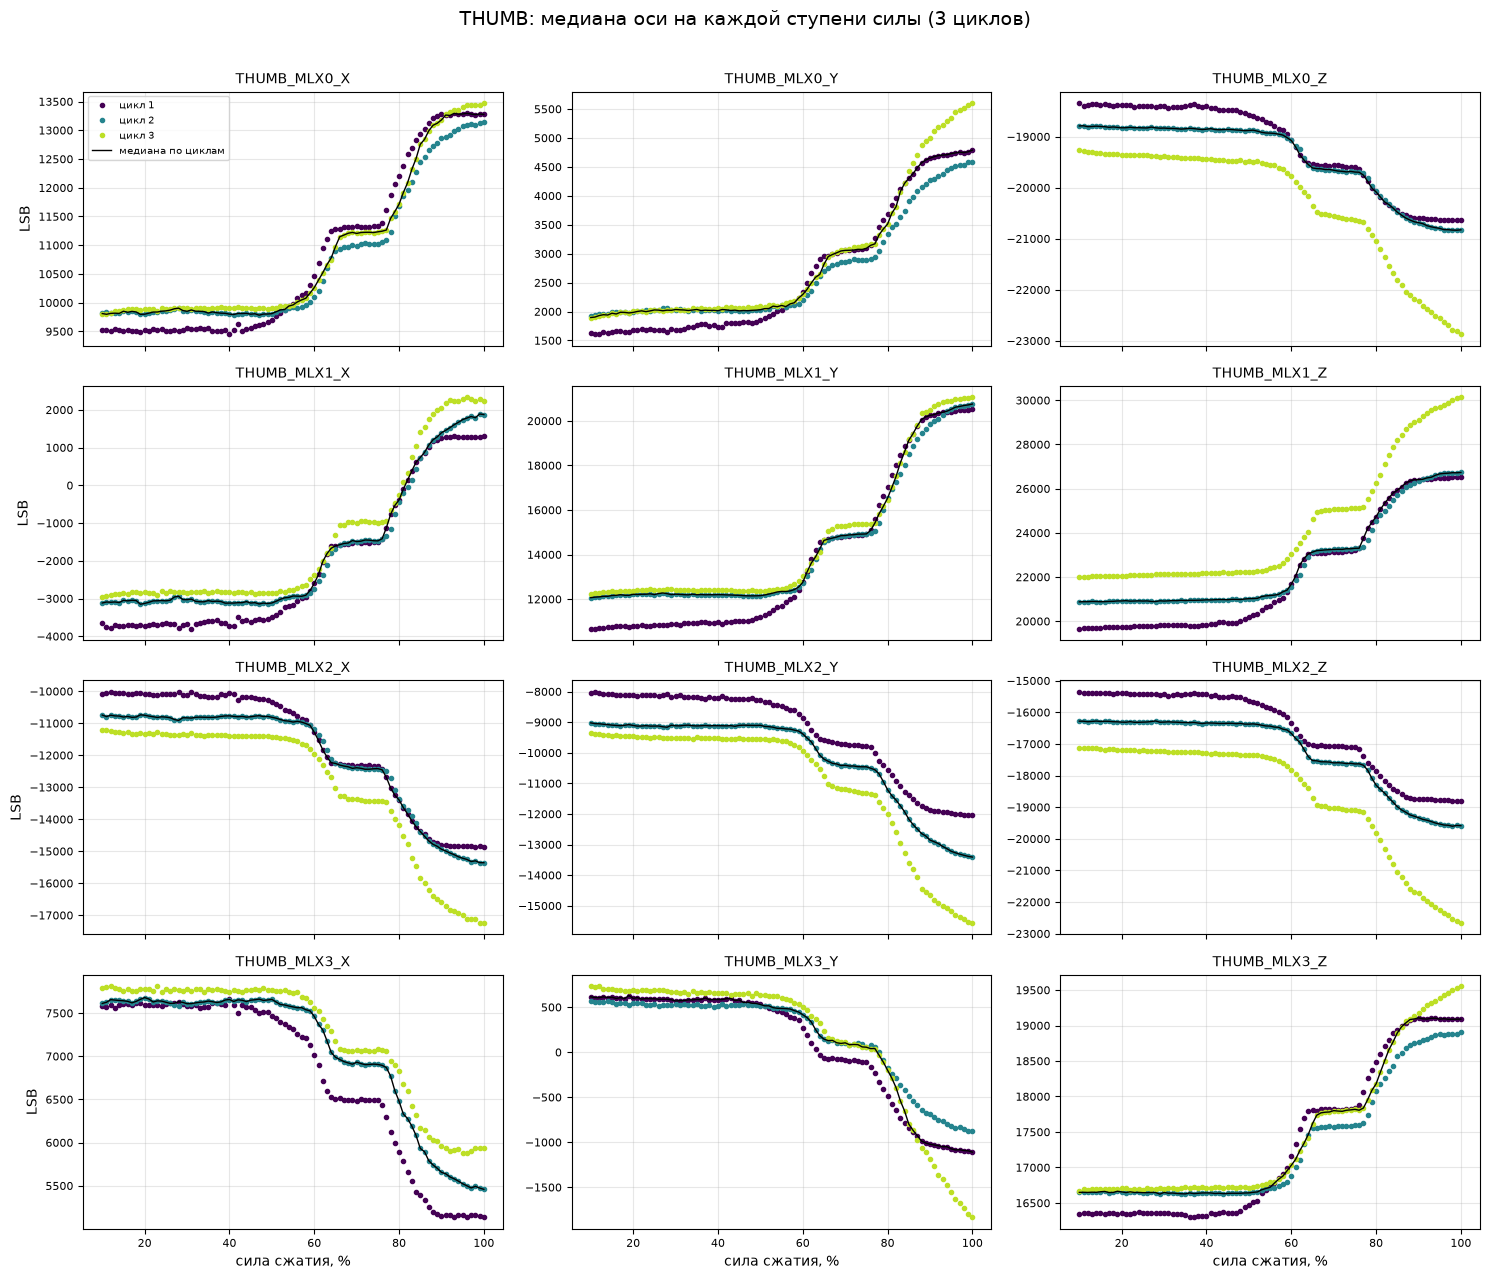

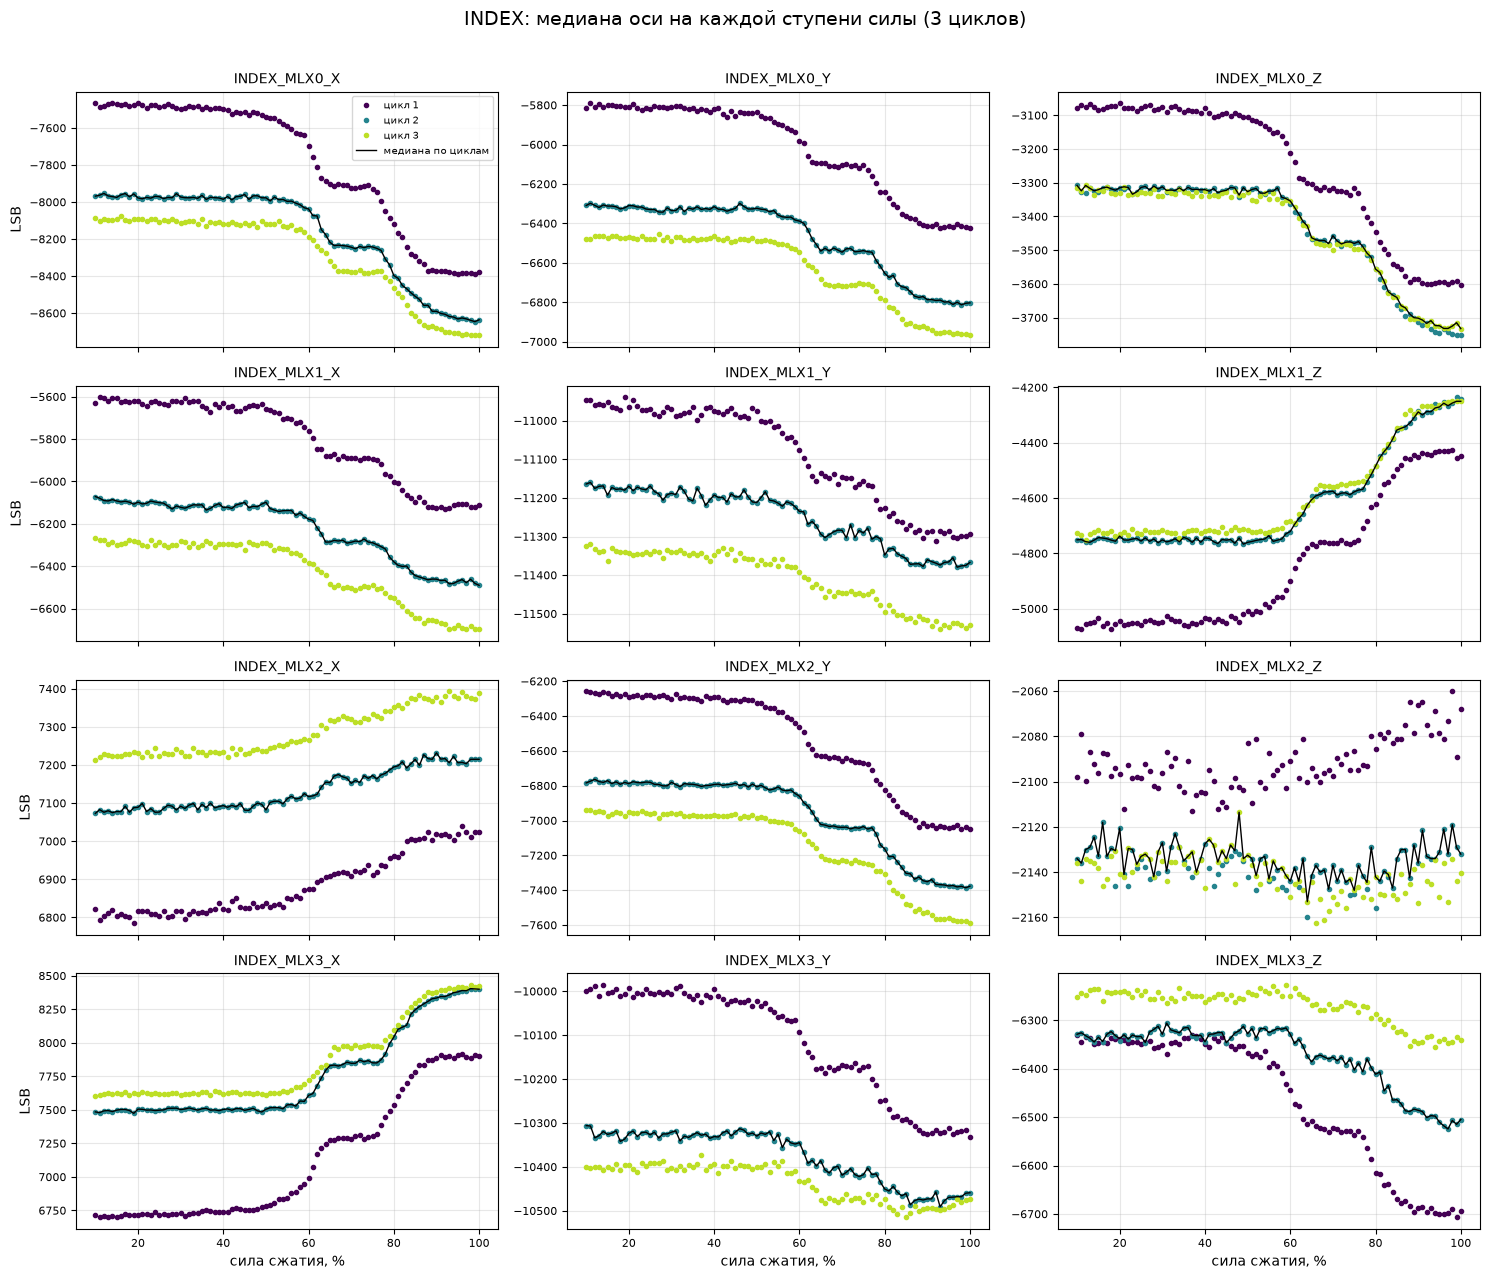

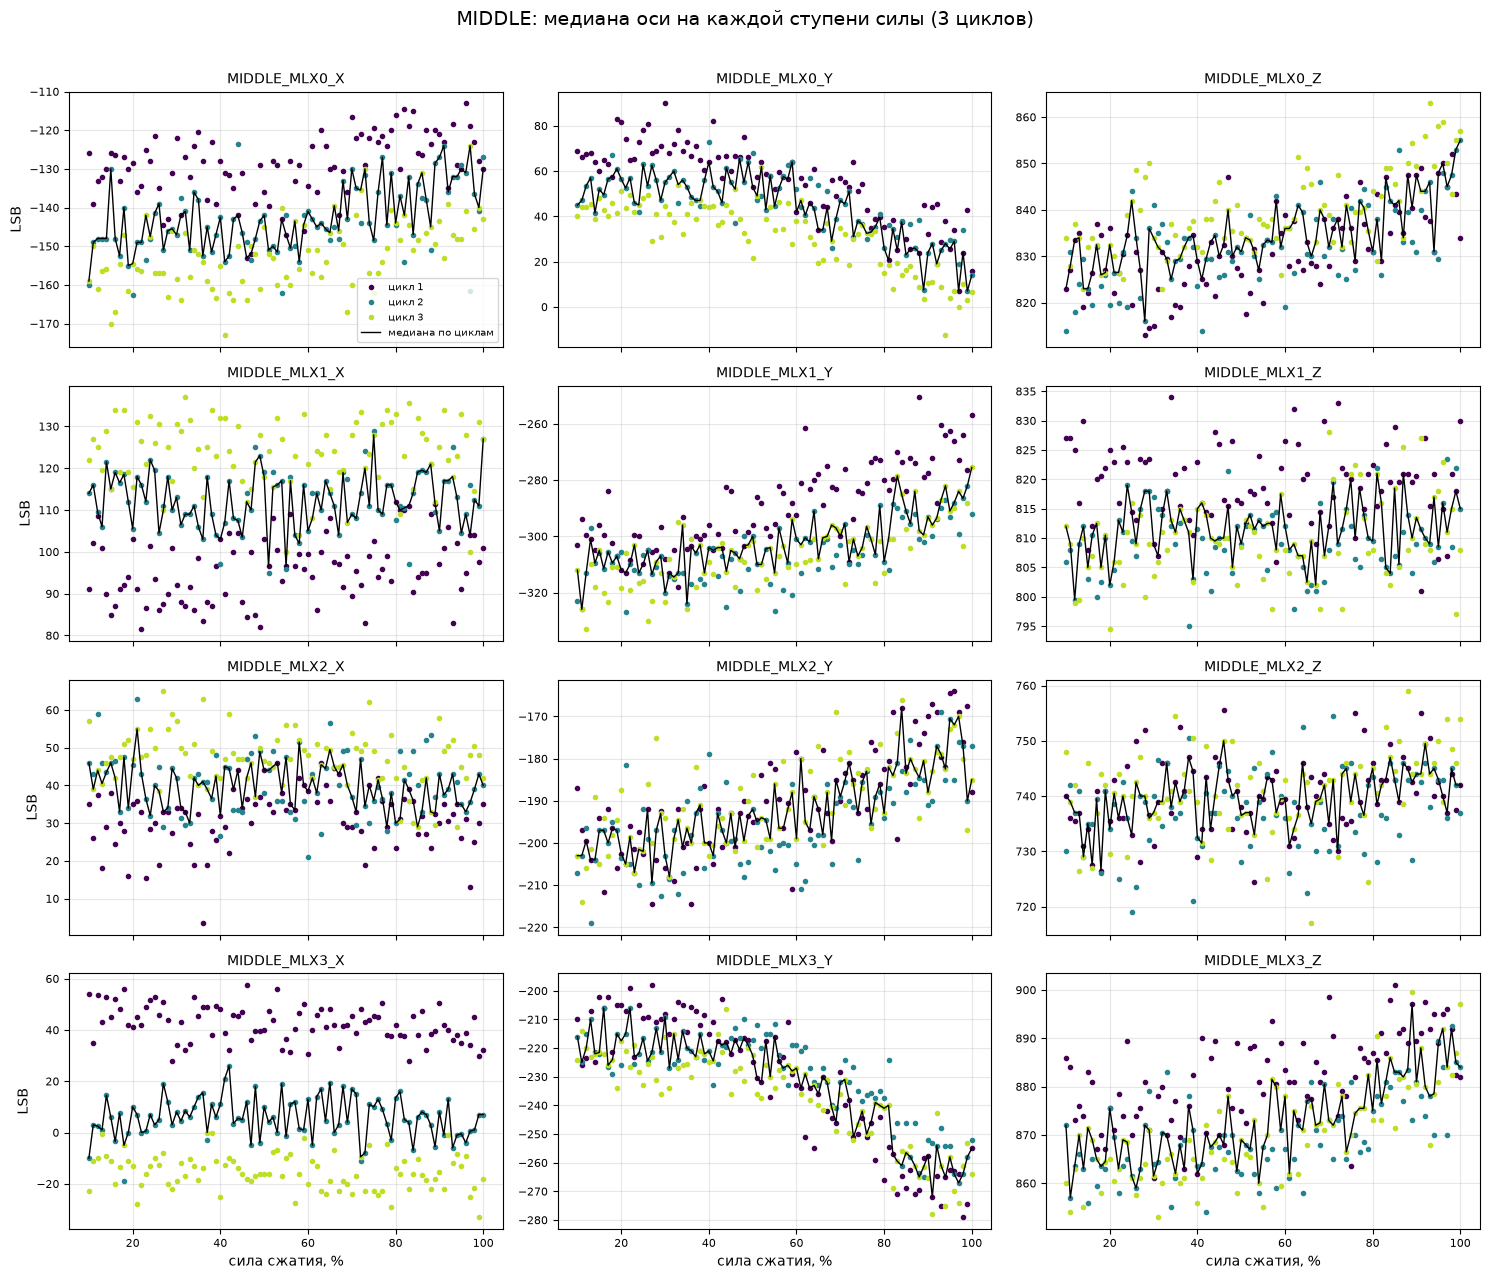

In [7]:
# --- графики: фигура на ячейку, сетка MLX (строки) × ось (столбцы), точки — циклы
colors = plt.cm.viridis(np.linspace(0, 0.9, n_cycles))

for cell in CELLS:
    fig, axs = plt.subplots(N_MLX, len(AXES), figsize=(15, 13), sharex=True)
    fig.suptitle(f'{cell}: медиана оси на каждой ступени силы ({n_cycles} циклов)', fontsize=14)
    for m in range(N_MLX):
        for a, axis in enumerate(AXES):
            ax = axs[m, a]
            i = col[f'{cell}_MLX{m}_{axis}']
            for c in range(n_cycles):
                ax.plot(levels, med[c, :, i], 'o', ms=3, color=colors[c], label=f'цикл {c + 1}')
            ax.plot(levels, med_all[:, i], '-', color='black', lw=1, label='медиана по циклам')
            ax.set_title(f'{cell}_MLX{m}_{axis}', fontsize=10)
            ax.grid(alpha=0.3)
            ax.tick_params(labelsize=8)
            if m == N_MLX - 1:
                ax.set_xlabel('сила сжатия, %')
            if a == 0:
                ax.set_ylabel('LSB')
    axs[0, 0].legend(fontsize=7, loc='best')
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    if SAVE_PNG:
        fig.savefig(f'{FILE.stem}_{cell}.png', dpi=110)
    plt.show()

In [8]:
# --- таблица медиан: cycle, force_pct, n_frames, все 36 осей (для дальнейшего анализа)
out = Path(f'{FILE.stem}_medians.csv')
with open(out, 'w', newline='', encoding='utf-8-sig') as fh:
    w = csv.writer(fh)
    w.writerow(['cycle', 'force_pct', 'n_frames'] + mag_names)
    for c in range(n_cycles):
        for j, L in enumerate(levels):
            if n_frames[c, j]:
                w.writerow([c + 1, L, n_frames[c, j]] + [f'{v:.1f}' for v in med[c, j]])
print('сохранено:', out.resolve())

сохранено: /home/max/python_projects/vtos_vtochku/analysis/ramp_20261027_133256_medians.csv
